# King County House Sales — Complete EDA & Data Cleaning

Complete notebook for `KC_House_Data.csv`: data overview, data quality, missing values, duplicates, descriptive statistics, graphs, bivariate analysis, correlation, invalid values, outliers, cleaning, and before/after comparison.


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")


## 2. Load Dataset

In [2]:
df = pd.read_csv("KC_House_Data.csv", low_memory=False)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (21613, 20)


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,20141013T000000,7700000,6,8.000,12050,27600,2.500,0,3,4,13,8570,3480,1910,1987,98102,47.630,-122.323,3940,8800
1,20140611T000000,7062500,5,4.500,10040,37325,2.000,1,2,3,11,7680,2360,1940,2001,98004,47.650,-122.214,3930,25449
2,20140919T000000,6885000,6,7.750,9890,31374,2.000,0,4,3,13,8860,1030,2001,0,98039,47.630,-122.240,4540,42730
3,20140804T000000,5570000,5,5.750,9200,35069,2.000,0,0,3,13,6200,3000,2001,0,98039,47.629,-122.233,3560,24345
4,20150413T000000,5350000,5,5.000,8000,23985,2.000,0,4,3,12,6720,1280,2009,0,98004,47.623,-122.220,4600,21750


## 3. Dataset Information

In [3]:
print(df.info())
overview = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null": df.notna().sum(),
    "Missing": df.isna().sum(),
    "Missing %": (df.isna().mean()*100).round(2),
    "Unique": df.nunique(dropna=True)
})
display(overview)


<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           21613 non-null  str    
 1   price          21613 non-null  int64  
 2   bedrooms       21613 non-null  int64  
 3   bathrooms      21613 non-null  float64
 4   sqft_living    21613 non-null  int64  
 5   sqft_lot       21613 non-null  int64  
 6   floors         21613 non-null  float64
 7   waterfront     21613 non-null  int64  
 8   view           21613 non-null  int64  
 9   condition      21613 non-null  int64  
 10  grade          21613 non-null  int64  
 11  sqft_above     21613 non-null  int64  
 12  sqft_basement  21613 non-null  int64  
 13  yr_built       21613 non-null  int64  
 14  yr_renovated   21613 non-null  int64  
 15  zipcode        21613 non-null  int64  
 16  lat            21613 non-null  float64
 17  long           21613 non-null  float64
 18  sqft_living15  21

,Data Type,Non-Null,Missing,Missing %,Unique
date,str,21613,0,0.000,372
price,int64,21613,0,0.000,4028
bedrooms,int64,21613,0,0.000,13
bathrooms,float64,21613,0,0.000,30
sqft_living,int64,21613,0,0.000,1038
sqft_lot,int64,21613,0,0.000,9782
floors,float64,21613,0,0.000,6
waterfront,int64,21613,0,0.000,2
view,int64,21613,0,0.000,5
condition,int64,21613,0,0.000,5


## 4. Variable Overview

`price` is the sale price and the main target of this analysis. The remaining fields describe room counts, living/lot area, construction quality (`condition`, `grade`), waterfront/view status, year built/renovated, and location (`zipcode`, `lat`, `long`).


## 5. Parse Date & Feature Engineering

In [4]:
df["date"]=pd.to_datetime(df["date"], format="%Y%m%dT%H%M%S", errors="coerce")
df["sale_year"]=df["date"].dt.year
df["sale_month"]=df["date"].dt.month
df["sale_day"]=df["date"].dt.day
df["sale_weekday"]=df["date"].dt.weekday
df["sale_weekday_name"]=df["date"].dt.day_name()
df["sale_quarter"]=df["date"].dt.quarter
df["is_weekend"]=df["date"].dt.weekday.isin([5,6]).astype(int)
df["house_age"]=df["sale_year"]-df["yr_built"]
df["was_renovated"]=(df["yr_renovated"]>0).astype(int)
df["years_since_renovation"]=np.where(df["yr_renovated"]>0,df["sale_year"]-df["yr_renovated"],df["house_age"])
df["price_per_sqft"]=df["price"]/df["sqft_living"]

display(df[["date","sale_year","sale_month","sale_day","sale_weekday_name","sale_quarter",
            "is_weekend","house_age","was_renovated","years_since_renovation","price_per_sqft"]].head())


,date,sale_year,sale_month,sale_day,sale_weekday_name,sale_quarter,is_weekend,house_age,was_renovated,years_since_renovation,price_per_sqft
0,2014-10-13,2014,10,13,Monday,4,0,104,1,27,639.004
1,2014-06-11,2014,6,11,Wednesday,2,0,74,1,13,703.436
2,2014-09-19,2014,9,19,Friday,3,0,13,0,13,696.158
3,2014-08-04,2014,8,4,Monday,3,0,13,0,13,605.435
4,2015-04-13,2015,4,13,Monday,2,0,6,0,6,668.750


## 6. Missing Values

In [5]:
missing = pd.DataFrame({
    "Missing Values": df.isna().sum(),
    "Missing Percentage": (df.isna().mean()*100).round(2)
}).sort_values("Missing Values", ascending=False)
display(missing)


,Missing Values,Missing Percentage
date,0,0.000
price,0,0.000
bedrooms,0,0.000
bathrooms,0,0.000
sqft_living,0,0.000
sqft_lot,0,0.000
floors,0,0.000
waterfront,0,0.000
view,0,0.000
condition,0,0.000


In [6]:
m = missing[missing["Missing Values"] > 0]
if len(m) > 0:
    plt.figure(figsize=(10,5))
    sns.barplot(x=m["Missing Percentage"].values, y=m.index)
    plt.title("Missing Values by Variable")
    plt.xlabel("Missing Percentage (%)")
    plt.ylabel("Variable")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values in this dataset.")


No missing values in this dataset.


## 7. Duplicate Records

In [7]:
print("Duplicate complete rows:", df.duplicated().sum())
print("Duplicate zipcode+date+price combos:", df.duplicated(subset=["date","price","zipcode","sqft_living"]).sum())


Duplicate complete rows: 0
Duplicate zipcode+date+price combos: 3


## 8. Target Variable Analysis (`price`)

In [8]:
display(df["price"].describe().to_frame("price"))


,price
count,"21,613.000"
mean,"540,088.142"
std,"367,127.196"
min,"75,000.000"
25%,"321,950.000"
50%,"450,000.000"
75%,"645,000.000"
max,"7,700,000.000"


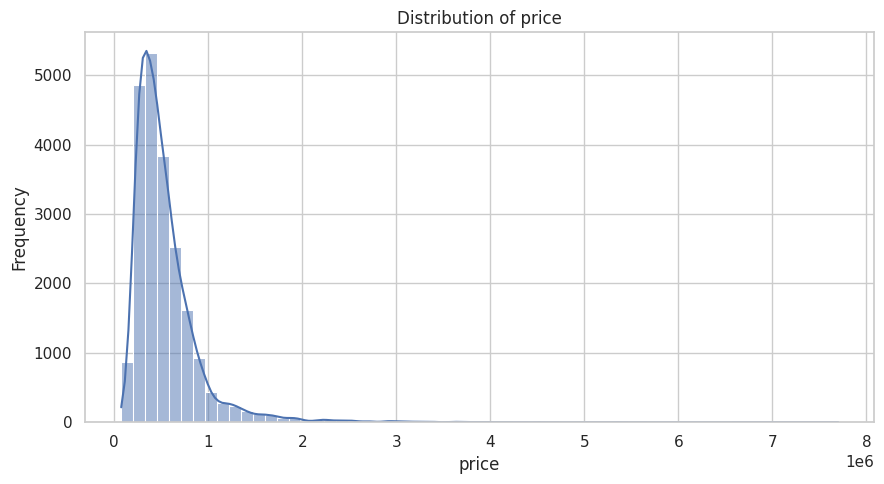

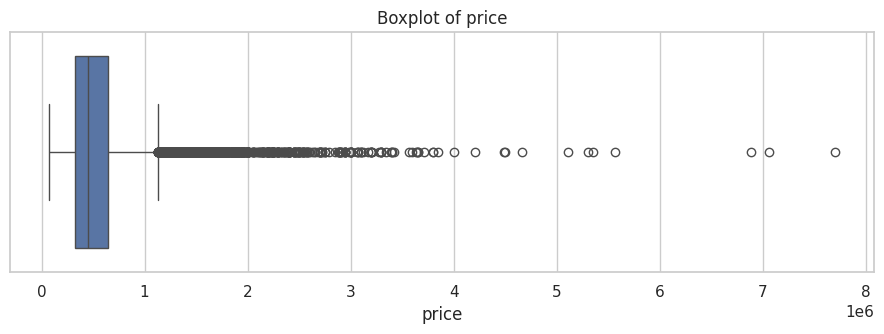

In [9]:
plt.figure(figsize=(9,5))
sns.histplot(df["price"], bins=60, kde=True)
plt.title("Distribution of price")
plt.xlabel("price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["price"])
plt.title("Boxplot of price")
plt.xlabel("price")
plt.tight_layout()
plt.show()


## 9. Log-Transformed Price

`price` is right-skewed, so a log transform is checked here for use in later modeling.

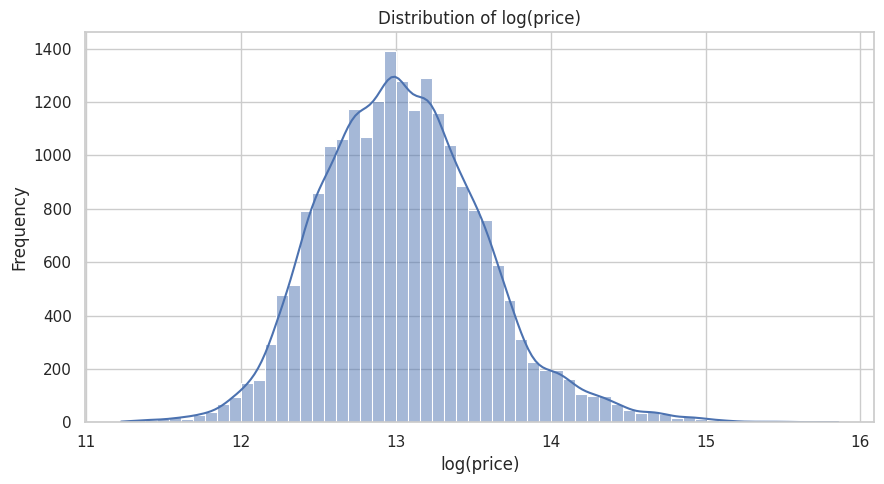

In [10]:
df["log_price"] = np.log1p(df["price"])
plt.figure(figsize=(9,5))
sns.histplot(df["log_price"], bins=60, kde=True)
plt.title("Distribution of log(price)")
plt.xlabel("log(price)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


## 10. Bedrooms Investigation

A quick check for suspicious values before trusting `bedrooms` in later analysis.

In [11]:
print("Bedrooms dtype:", df["bedrooms"].dtype)
display(df["bedrooms"].value_counts().sort_index())
print("Max bedrooms:", df["bedrooms"].max())
display(df[df["bedrooms"] > 10][["bedrooms","bathrooms","sqft_living","price"]])


Bedrooms dtype: int64


bedrooms
0       13
1      199
2     2760
3     9824
4     6882
5     1601
6      272
7       38
8       13
9        6
10       3
11       1
33       1
Name: count, dtype: int64

Max bedrooms: 33


,bedrooms,bathrooms,sqft_living,price
5479,33,1.750,1620,640000
8598,11,3.000,3000,520000


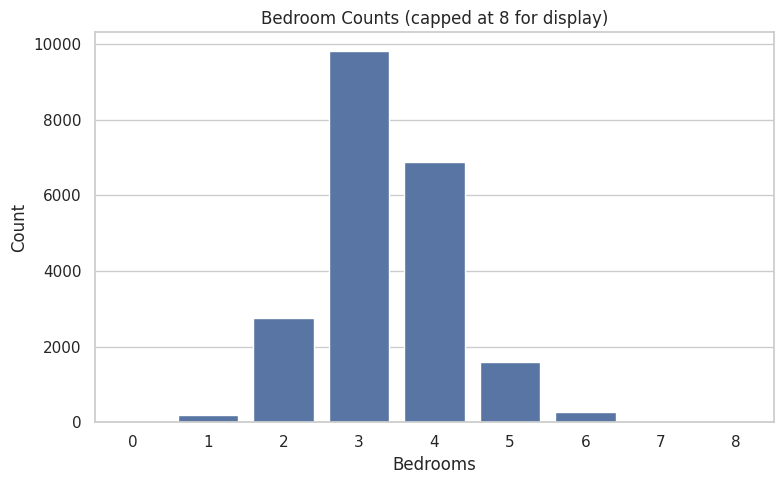

In [12]:
b = df["bedrooms"].clip(upper=8).value_counts().sort_index()
plt.figure(figsize=(8,5))
sns.barplot(x=b.index, y=b.values)
plt.title("Bedroom Counts (capped at 8 for display)")
plt.xlabel("Bedrooms")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


## 11. Descriptive Statistics

In [13]:
display(df.describe(include="all").T)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,21613,NaN,NaN,NaN,2014-10-29 04:38:01.959931,2014-05-02 00:00:00,2014-07-22 00:00:00,2014-10-16 00:00:00,2015-02-17 00:00:00,2015-05-27 00:00:00,NaN
price,"21,613.000",NaN,NaN,NaN,"540,088.142","75,000.000","321,950.000","450,000.000","645,000.000","7,700,000.000","367,127.196"
bedrooms,"21,613.000",NaN,NaN,NaN,3.371,0.000,3.000,3.000,4.000,33.000,0.930
bathrooms,"21,613.000",NaN,NaN,NaN,2.115,0.000,1.750,2.250,2.500,8.000,0.770
sqft_living,"21,613.000",NaN,NaN,NaN,"2,079.900",290.000,"1,427.000","1,910.000","2,550.000","13,540.000",918.441
sqft_lot,"21,613.000",NaN,NaN,NaN,"15,106.968",520.000,"5,040.000","7,618.000","10,688.000","1,651,359.000","41,420.512"
floors,"21,613.000",NaN,NaN,NaN,1.494,1.000,1.000,1.500,2.000,3.500,0.540
waterfront,"21,613.000",NaN,NaN,NaN,0.008,0.000,0.000,0.000,0.000,1.000,0.087
view,"21,613.000",NaN,NaN,NaN,0.234,0.000,0.000,0.000,0.000,4.000,0.766
condition,"21,613.000",NaN,NaN,NaN,3.409,1.000,3.000,3.000,4.000,5.000,0.651


## 12. Numerical Distributions and Boxplots

In [14]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_predictors = [c for c in numeric_cols if c not in ["price","log_price","price_per_sqft","zipcode","lat","long"]]
print(numeric_predictors)


['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'sale_day', 'sale_weekday', 'sale_quarter', 'is_weekend', 'house_age', 'was_renovated', 'years_since_renovation']


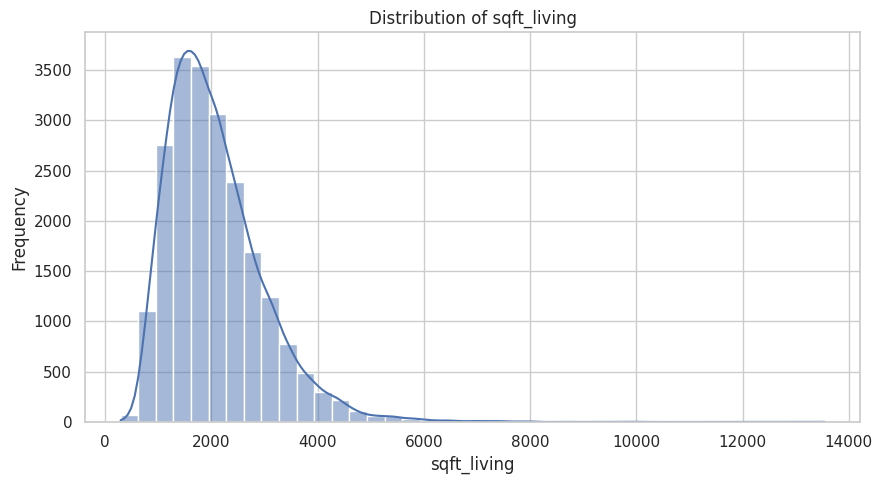

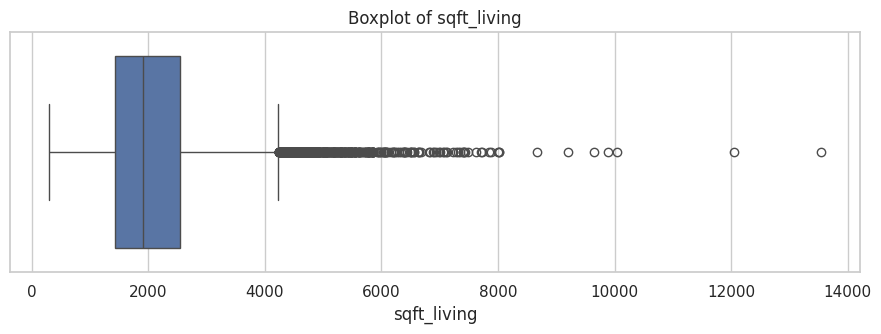

In [15]:
plt.figure(figsize=(9,5))
sns.histplot(df["sqft_living"].dropna(), bins=40, kde=True)
plt.title("Distribution of sqft_living")
plt.xlabel("sqft_living")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["sqft_living"])
plt.title("Boxplot of sqft_living")
plt.xlabel("sqft_living")
plt.tight_layout()
plt.show()


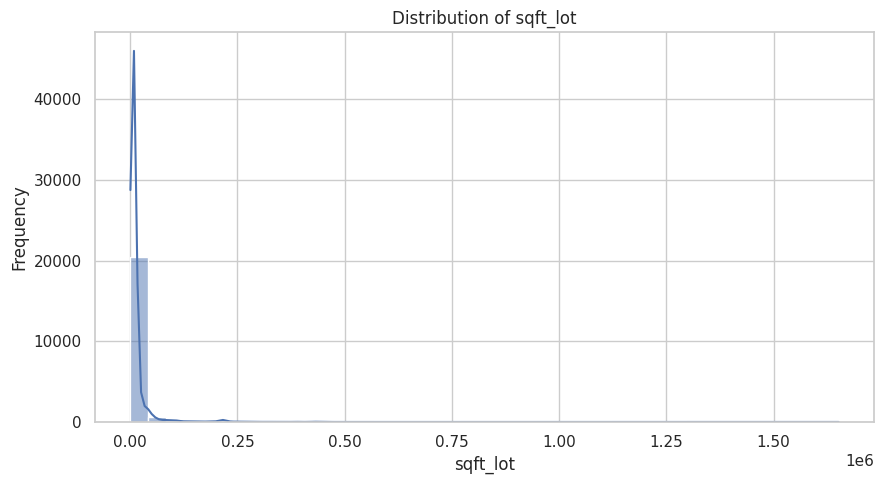

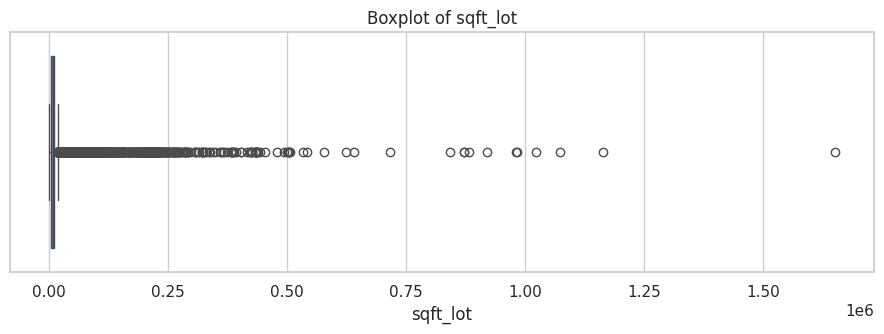

In [16]:
plt.figure(figsize=(9,5))
sns.histplot(df["sqft_lot"].dropna(), bins=40, kde=True)
plt.title("Distribution of sqft_lot")
plt.xlabel("sqft_lot")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["sqft_lot"])
plt.title("Boxplot of sqft_lot")
plt.xlabel("sqft_lot")
plt.tight_layout()
plt.show()


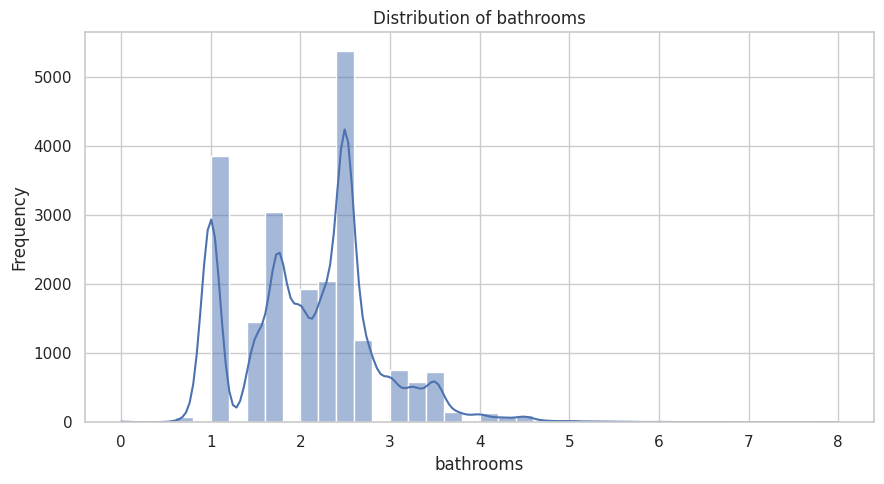

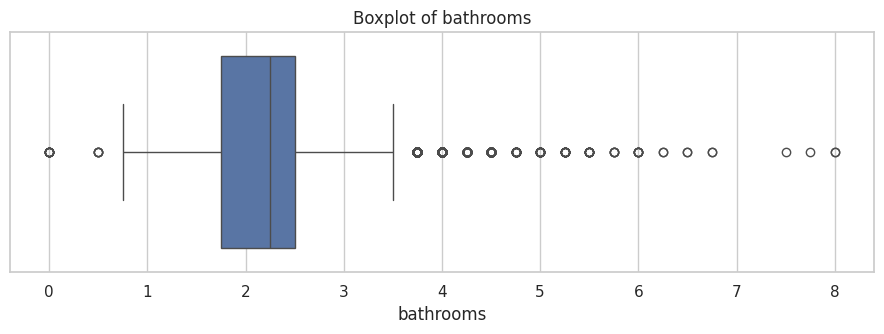

In [17]:
plt.figure(figsize=(9,5))
sns.histplot(df["bathrooms"].dropna(), bins=40, kde=True)
plt.title("Distribution of bathrooms")
plt.xlabel("bathrooms")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["bathrooms"])
plt.title("Boxplot of bathrooms")
plt.xlabel("bathrooms")
plt.tight_layout()
plt.show()


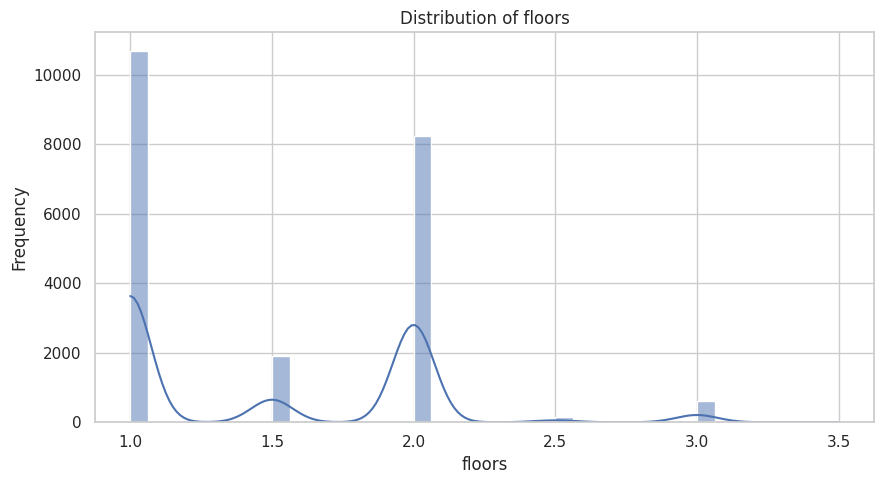

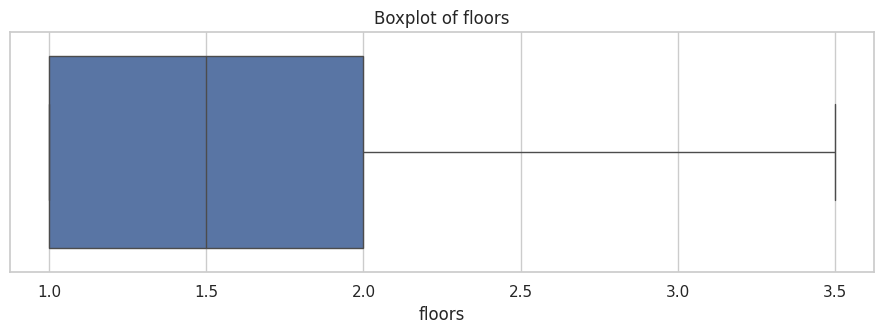

In [18]:
plt.figure(figsize=(9,5))
sns.histplot(df["floors"].dropna(), bins=40, kde=True)
plt.title("Distribution of floors")
plt.xlabel("floors")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["floors"])
plt.title("Boxplot of floors")
plt.xlabel("floors")
plt.tight_layout()
plt.show()


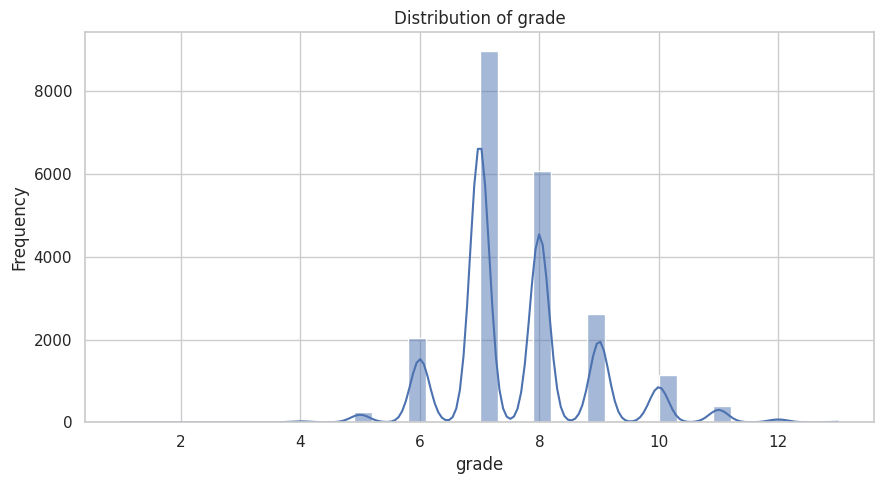

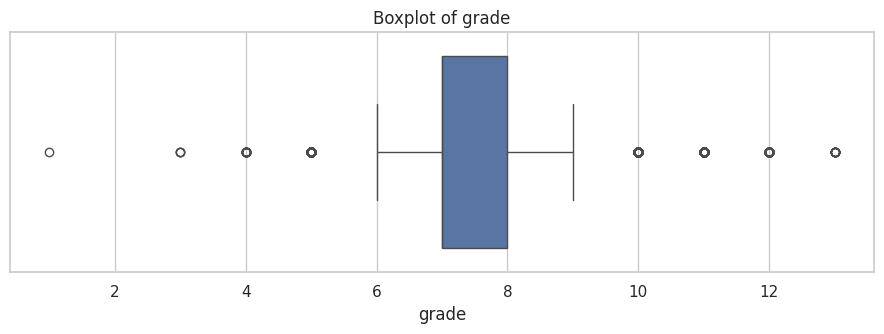

In [19]:
plt.figure(figsize=(9,5))
sns.histplot(df["grade"].dropna(), bins=40, kde=True)
plt.title("Distribution of grade")
plt.xlabel("grade")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["grade"])
plt.title("Boxplot of grade")
plt.xlabel("grade")
plt.tight_layout()
plt.show()


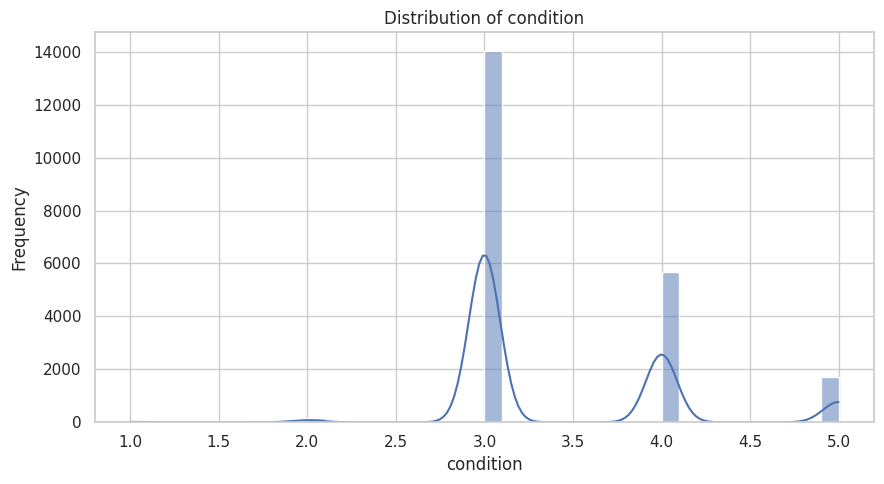

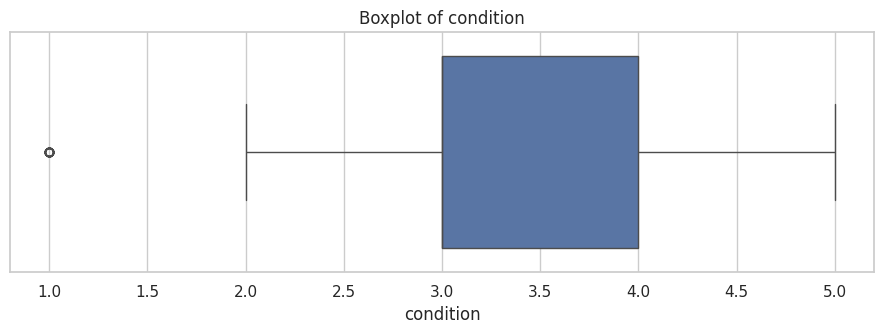

In [20]:
plt.figure(figsize=(9,5))
sns.histplot(df["condition"].dropna(), bins=40, kde=True)
plt.title("Distribution of condition")
plt.xlabel("condition")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["condition"])
plt.title("Boxplot of condition")
plt.xlabel("condition")
plt.tight_layout()
plt.show()


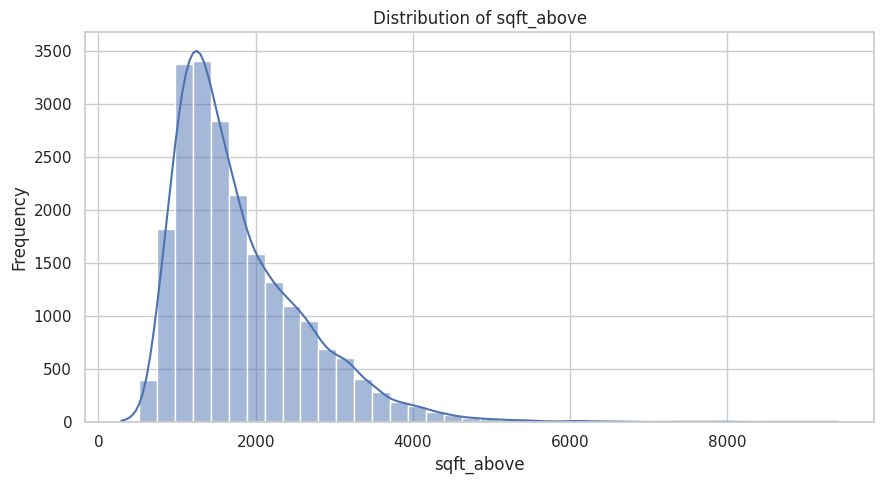

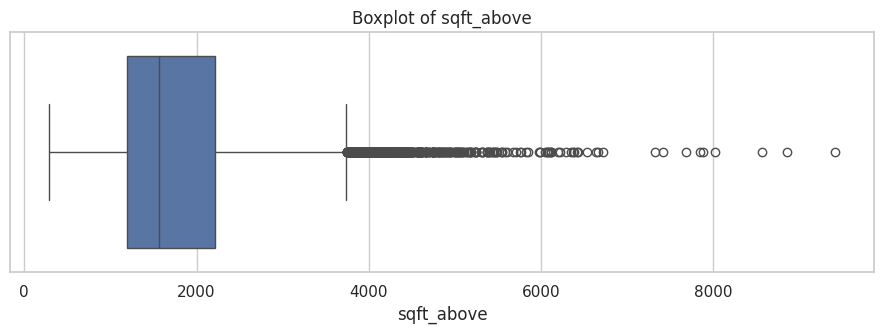

In [21]:
plt.figure(figsize=(9,5))
sns.histplot(df["sqft_above"].dropna(), bins=40, kde=True)
plt.title("Distribution of sqft_above")
plt.xlabel("sqft_above")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["sqft_above"])
plt.title("Boxplot of sqft_above")
plt.xlabel("sqft_above")
plt.tight_layout()
plt.show()


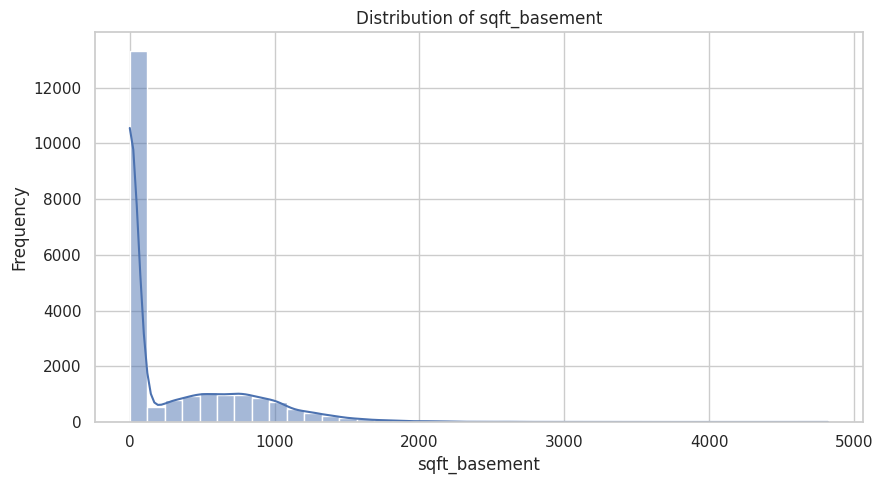

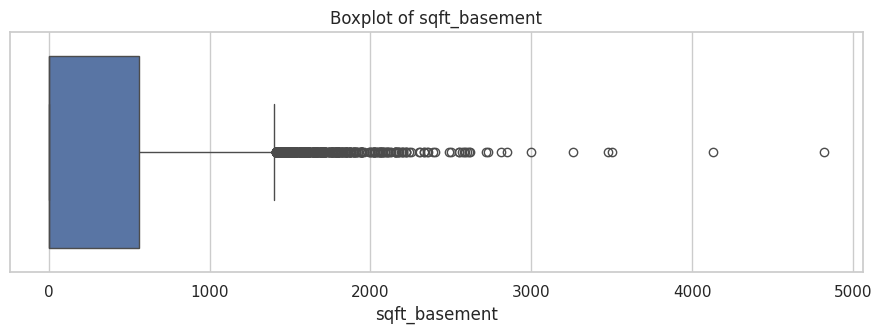

In [22]:
plt.figure(figsize=(9,5))
sns.histplot(df["sqft_basement"].dropna(), bins=40, kde=True)
plt.title("Distribution of sqft_basement")
plt.xlabel("sqft_basement")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["sqft_basement"])
plt.title("Boxplot of sqft_basement")
plt.xlabel("sqft_basement")
plt.tight_layout()
plt.show()


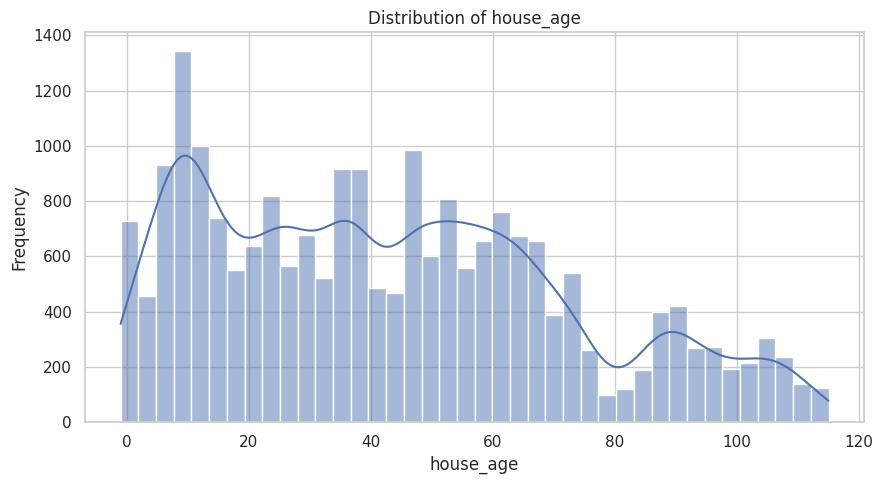

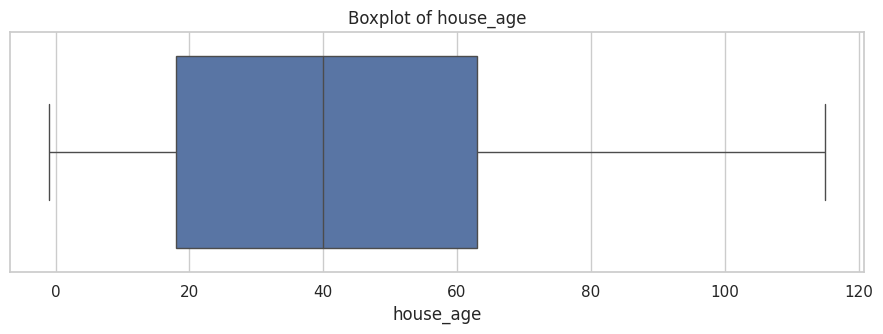

In [23]:
plt.figure(figsize=(9,5))
sns.histplot(df["house_age"].dropna(), bins=40, kde=True)
plt.title("Distribution of house_age")
plt.xlabel("house_age")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["house_age"])
plt.title("Boxplot of house_age")
plt.xlabel("house_age")
plt.tight_layout()
plt.show()


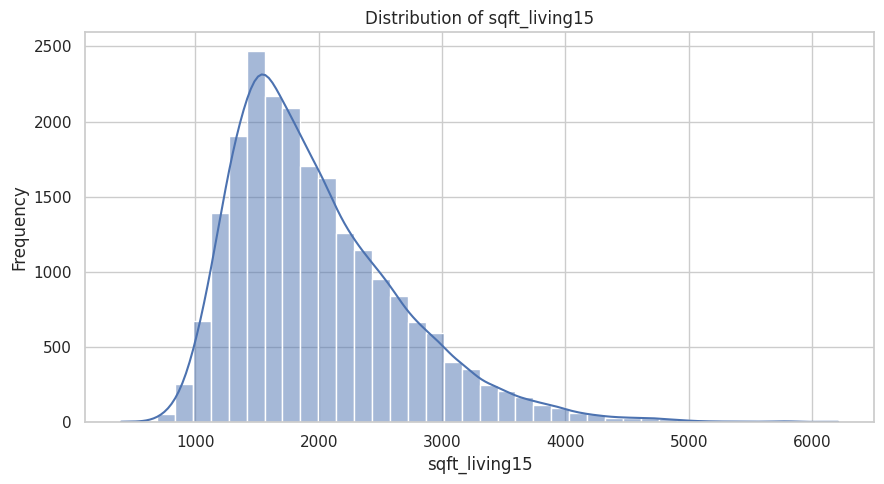

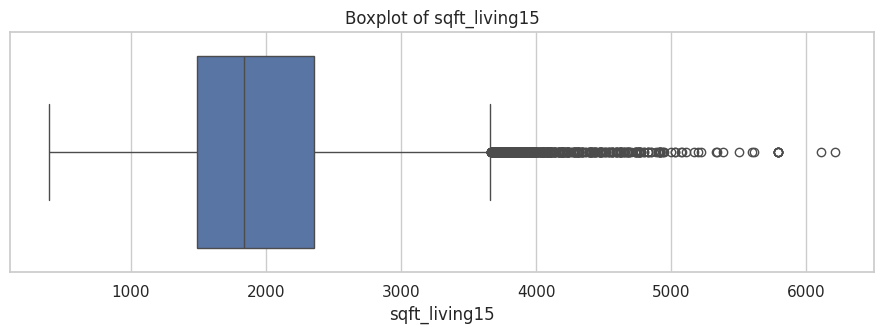

In [24]:
plt.figure(figsize=(9,5))
sns.histplot(df["sqft_living15"].dropna(), bins=40, kde=True)
plt.title("Distribution of sqft_living15")
plt.xlabel("sqft_living15")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9,3.5))
sns.boxplot(x=df["sqft_living15"])
plt.title("Boxplot of sqft_living15")
plt.xlabel("sqft_living15")
plt.tight_layout()
plt.show()


## 13. Bivariate Analysis — Important Variables vs Price

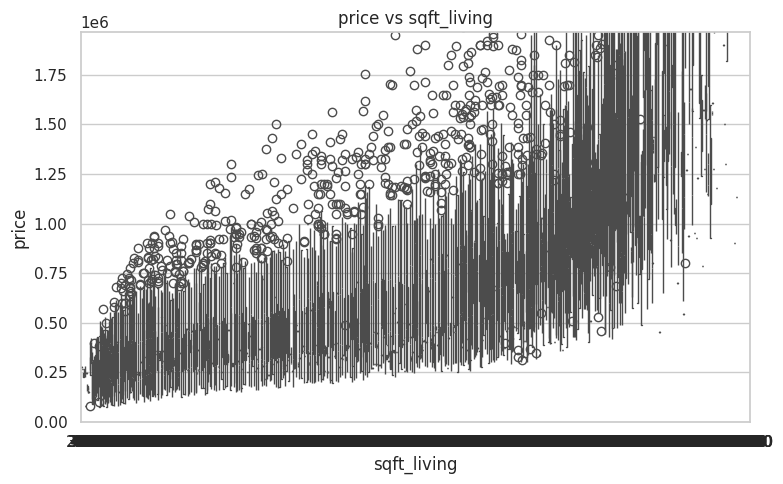

In [25]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="sqft_living", y="price")
plt.title("price vs sqft_living")
plt.xlabel("sqft_living")
plt.ylabel("price")
upper = df["price"].quantile(.99)
if np.isfinite(upper) and upper > 0:
    plt.ylim(0, upper)
plt.tight_layout()
plt.show()


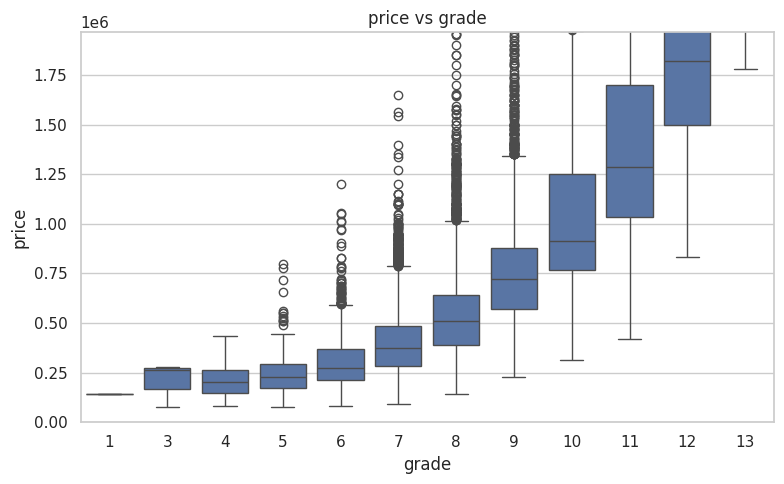

In [26]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="grade", y="price")
plt.title("price vs grade")
plt.xlabel("grade")
plt.ylabel("price")
upper = df["price"].quantile(.99)
if np.isfinite(upper) and upper > 0:
    plt.ylim(0, upper)
plt.tight_layout()
plt.show()


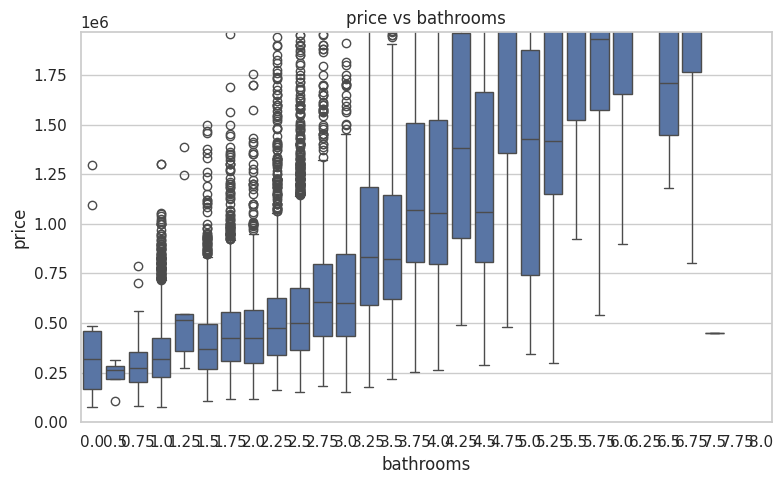

In [27]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="bathrooms", y="price")
plt.title("price vs bathrooms")
plt.xlabel("bathrooms")
plt.ylabel("price")
upper = df["price"].quantile(.99)
if np.isfinite(upper) and upper > 0:
    plt.ylim(0, upper)
plt.tight_layout()
plt.show()


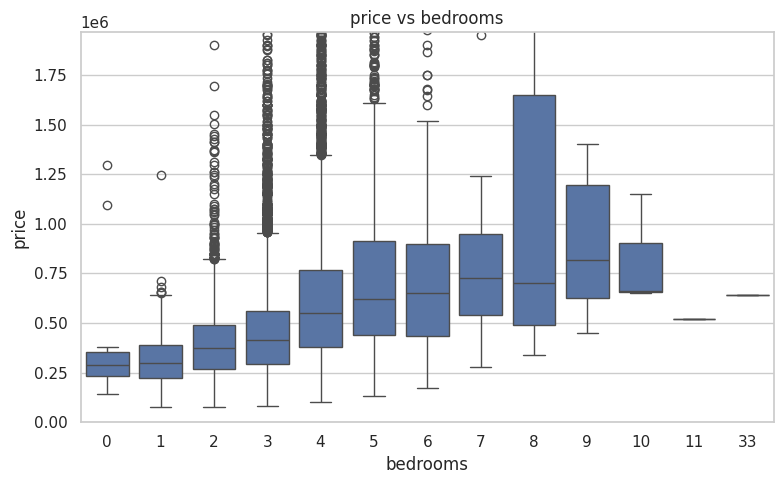

In [28]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="bedrooms", y="price")
plt.title("price vs bedrooms")
plt.xlabel("bedrooms")
plt.ylabel("price")
upper = df["price"].quantile(.99)
if np.isfinite(upper) and upper > 0:
    plt.ylim(0, upper)
plt.tight_layout()
plt.show()


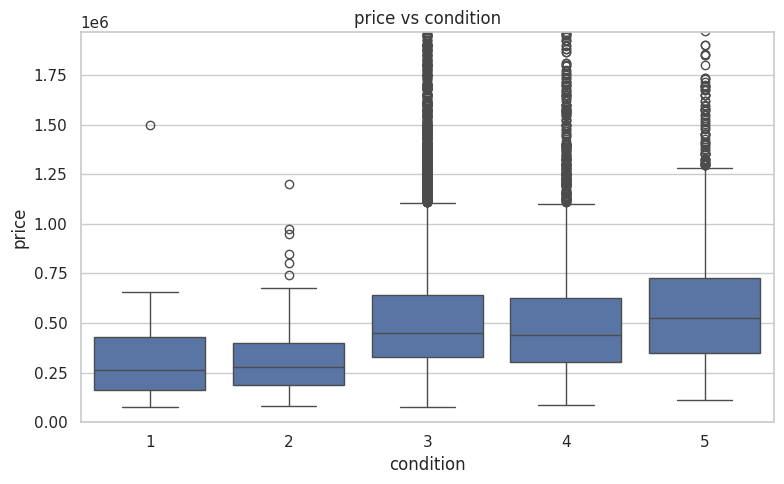

In [29]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="condition", y="price")
plt.title("price vs condition")
plt.xlabel("condition")
plt.ylabel("price")
upper = df["price"].quantile(.99)
if np.isfinite(upper) and upper > 0:
    plt.ylim(0, upper)
plt.tight_layout()
plt.show()


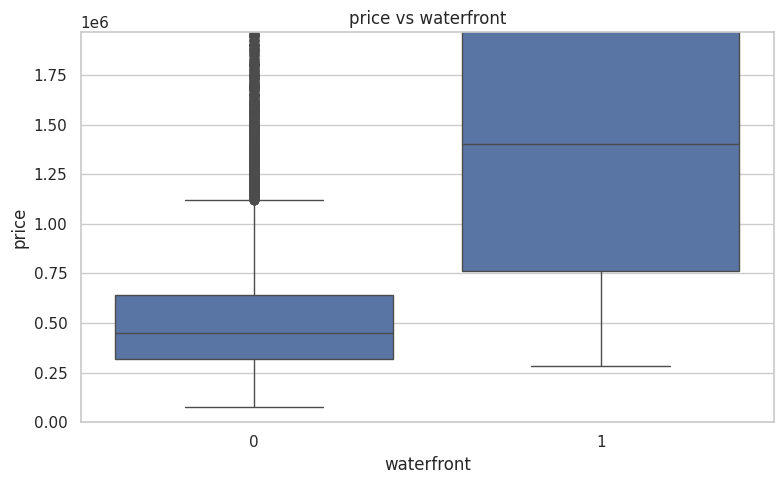

In [30]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="waterfront", y="price")
plt.title("price vs waterfront")
plt.xlabel("waterfront")
plt.ylabel("price")
upper = df["price"].quantile(.99)
if np.isfinite(upper) and upper > 0:
    plt.ylim(0, upper)
plt.tight_layout()
plt.show()


## 14. Scatter: Price vs Living Area

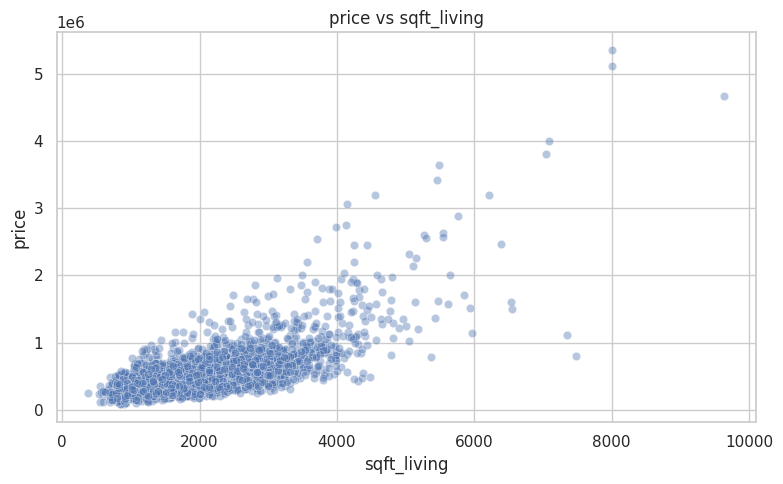

In [31]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df.sample(3000, random_state=1), x="sqft_living", y="price", alpha=0.4)
plt.title("price vs sqft_living")
plt.xlabel("sqft_living")
plt.ylabel("price")
plt.tight_layout()
plt.show()


## 15. Average Price by House Age Group

In [32]:
bins = [0,10,20,30,40,50,75,100,np.inf]
labels = ["0-10","11-20","21-30","31-40","41-50","51-75","76-100","100+"]
tmp = df.copy()
tmp["AgeGroup"] = pd.cut(tmp["house_age"], bins=bins, labels=labels, include_lowest=True)
age_price = tmp.groupby("AgeGroup", observed=False)["price"].mean().reset_index(name="Average Price")
display(age_price)


,AgeGroup,Average Price
0,0-10,"615,793.023"
1,11-20,"612,120.860"
2,21-30,"550,926.448"
3,31-40,"498,761.283"
4,41-50,"464,821.166"
5,51-75,"466,174.029"
6,76-100,"589,888.391"
7,100+,"631,701.989"


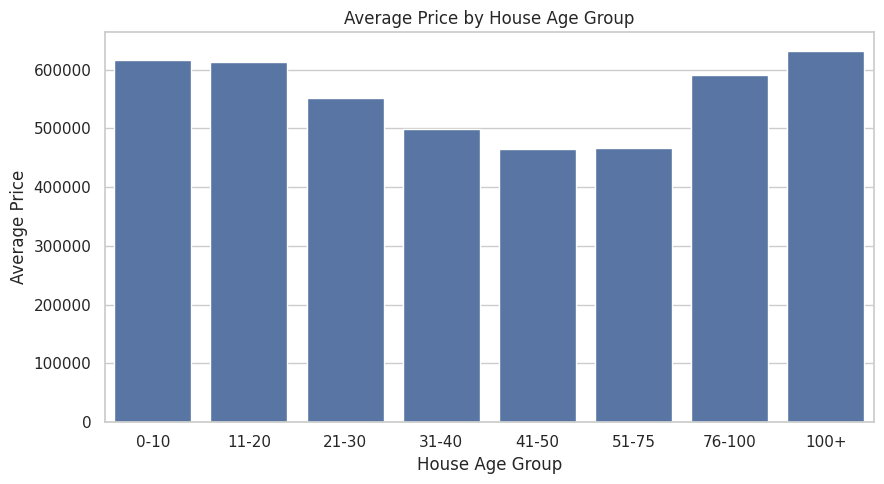

In [33]:
plt.figure(figsize=(9,5))
sns.barplot(data=age_price, x="AgeGroup", y="Average Price")
plt.title("Average Price by House Age Group")
plt.xlabel("House Age Group")
plt.ylabel("Average Price")
plt.tight_layout()
plt.show()


## 16. Waterfront & Renovation vs Price

In [34]:
for col in ["waterfront","was_renovated"]:
    print("\n", col)
    s = df.groupby(col)["price"].agg(["count","mean","median"]).reset_index()
    display(s)



 waterfront


,waterfront,count,mean,median
0,0,21450,"531,563.600","450,000.000"
1,1,163,"1,661,876.025","1,400,000.000"



 was_renovated


,was_renovated,count,mean,median
0,0,20699,"530,360.818","448,000.000"
1,1,914,"760,379.030","600,000.000"


## 17. Correlation Matrix

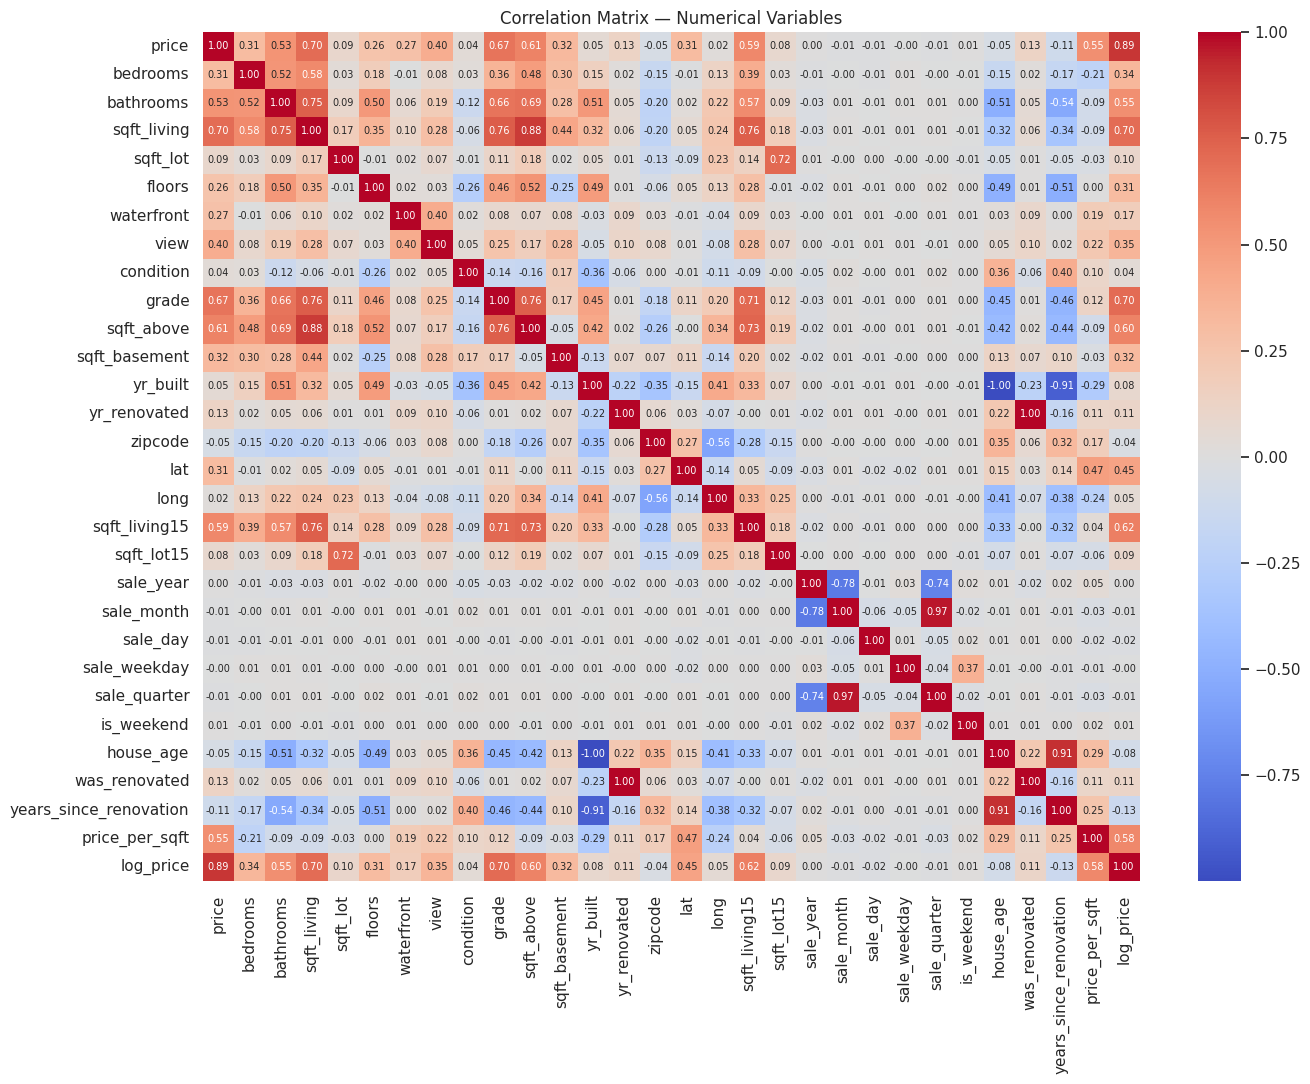

In [35]:
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(14,11))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size":7})
plt.title("Correlation Matrix — Numerical Variables")
plt.tight_layout()
plt.show()


In [36]:
display(corr["price"].drop(["price","log_price","price_per_sqft"]).sort_values(key=abs, ascending=False).to_frame("Correlation with price"))


,Correlation with price
sqft_living,0.702
grade,0.667
sqft_above,0.606
sqft_living15,0.585
bathrooms,0.525
view,0.397
sqft_basement,0.324
bedrooms,0.308
lat,0.307
waterfront,0.266


## 18. Invalid / Suspicious Values

In [37]:
checks = {
    "bedrooms == 0": int((df["bedrooms"]==0).sum()),
    "bedrooms > 10": int((df["bedrooms"]>10).sum()),
    "bathrooms == 0": int((df["bathrooms"]==0).sum()),
    "sqft_living <= 0": int((df["sqft_living"]<=0).sum()),
    "price <= 0": int((df["price"]<=0).sum()),
    "yr_renovated between 1 and 1900": int(((df["yr_renovated"]>0) & (df["yr_renovated"]<1900)).sum()),
    "yr_built > sale_year": int((df["yr_built"]>df["sale_year"]).sum())
}
check_table = pd.DataFrame.from_dict(checks, orient="index", columns=["Count"])
display(check_table)


,Count
bedrooms == 0,13
bedrooms > 10,2
bathrooms == 0,10
sqft_living <= 0,0
price <= 0,0
yr_renovated between 1 and 1900,0
yr_built > sale_year,12


## 19. Bedrooms = 33 Investigation

The dataset contains one record with 33 bedrooms on a modest living area, which is almost certainly a data-entry error (likely meant to be 3).

In [38]:
display(df[df["bedrooms"]==33][["bedrooms","bathrooms","sqft_living","sqft_lot","price"]])


,bedrooms,bathrooms,sqft_living,sqft_lot,price
5479,33,1.750,1620,6000,640000


## 20. IQR Outlier Summary

In [39]:
rows = []
for col in numeric_predictors:
    s = df[col].dropna()
    q1 = s.quantile(.25)
    q3 = s.quantile(.75)
    iqr = q3 - q1
    lo = q1 - 1.5*iqr
    hi = q3 + 1.5*iqr
    count = int(((df[col]<lo)|(df[col]>hi)).sum())
    rows.append([col, q1, q3, iqr, lo, hi, count, round(count/len(df)*100,2)])

outliers = pd.DataFrame(rows, columns=[
    "Variable","Q1","Q3","IQR","Lower Bound","Upper Bound","IQR Outliers","Outlier %"
]).sort_values("IQR Outliers", ascending=False)
display(outliers)


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,IQR Outliers,Outlier %
3,sqft_lot,"5,040.000","10,688.000","5,648.000","-3,432.000","19,160.000",2425,11.220
14,sqft_lot15,"5,100.000","10,083.000","4,983.000","-2,374.500","17,557.500",2194,10.150
6,view,0.000,0.000,0.000,0.000,0.000,2124,9.830
8,grade,7.000,8.000,1.000,5.500,9.500,1911,8.840
22,was_renovated,0.000,0.000,0.000,0.000,0.000,914,4.230
12,yr_renovated,0.000,0.000,0.000,0.000,0.000,914,4.230
9,sqft_above,"1,190.000","2,210.000","1,020.000",-340.000,"3,740.000",611,2.830
2,sqft_living,"1,427.000","2,550.000","1,123.000",-257.500,"4,234.500",572,2.650
1,bathrooms,1.750,2.500,0.750,0.625,3.625,571,2.640
0,bedrooms,3.000,4.000,1.000,1.500,5.500,546,2.530


## 21. Data Cleaning Strategy

The original `df` is preserved and a separate `df_clean` is created.

- Remove exact duplicate rows.
- Fix the `bedrooms == 33` record (treated as a data-entry error; corrected to 3 based on `sqft_living`/`bathrooms`).
- Drop `bedrooms == 0` and `bathrooms == 0` records with nonzero `sqft_living` (likely land or data-entry issues), if any.
- Keep `yr_renovated == 0` as "never renovated" (already captured by the `was_renovated` flag) rather than treating it as missing.
- Do not automatically delete high-price or high-`sqft_lot` outliers — these are legitimate luxury/rural properties; flag them instead of removing them.


In [40]:
df_clean = df.copy()
df_clean = df_clean.drop_duplicates().copy()

df_clean.loc[df_clean["bedrooms"]==33, "bedrooms"] = 3

invalid_mask = (df_clean["bedrooms"]==0) & (df_clean["bathrooms"]==0)
df_clean = df_clean.loc[~invalid_mask].copy()

print("Cleaning completed.")


Cleaning completed.


## 22. Original vs Cleaned Dataset

In [41]:
comparison = pd.DataFrame({
    "Dataset": ["Original","Cleaned"],
    "Rows": [df.shape[0], df_clean.shape[0]],
    "Columns": [df.shape[1], df_clean.shape[1]]
})
display(comparison)

missing_compare = pd.DataFrame({
    "Original Missing": df.isna().sum(),
    "Cleaned Missing": df_clean.isna().sum()
})
display(missing_compare)


,Dataset,Rows,Columns
0,Original,21613,32
1,Cleaned,21606,32


,Original Missing,Cleaned Missing
date,0,0
price,0,0
bedrooms,0,0
bathrooms,0,0
sqft_living,0,0
sqft_lot,0,0
floors,0,0
waterfront,0,0
view,0,0
condition,0,0


## 23. Cleaned Dataset Preview

In [42]:
display(df_clean.head())
df_clean.info()


,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month,sale_day,sale_weekday,sale_weekday_name,sale_quarter,is_weekend,house_age,was_renovated,years_since_renovation,price_per_sqft,log_price
0,2014-10-13,7700000,6,8.000,12050,27600,2.500,0,3,4,13,8570,3480,1910,1987,98102,47.630,-122.323,3940,8800,2014,10,13,0,Monday,4,0,104,1,27,639.004,15.857
1,2014-06-11,7062500,5,4.500,10040,37325,2.000,1,2,3,11,7680,2360,1940,2001,98004,47.650,-122.214,3930,25449,2014,6,11,2,Wednesday,2,0,74,1,13,703.436,15.770
2,2014-09-19,6885000,6,7.750,9890,31374,2.000,0,4,3,13,8860,1030,2001,0,98039,47.630,-122.240,4540,42730,2014,9,19,4,Friday,3,0,13,0,13,696.158,15.745
3,2014-08-04,5570000,5,5.750,9200,35069,2.000,0,0,3,13,6200,3000,2001,0,98039,47.629,-122.233,3560,24345,2014,8,4,0,Monday,3,0,13,0,13,605.435,15.533
4,2015-04-13,5350000,5,5.000,8000,23985,2.000,0,4,3,12,6720,1280,2009,0,98004,47.623,-122.220,4600,21750,2015,4,13,0,Monday,2,0,6,0,6,668.750,15.493


<class 'pandas.DataFrame'>
Index: 21606 entries, 0 to 21612
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   date                    21606 non-null  datetime64[us]
 1   price                   21606 non-null  int64         
 2   bedrooms                21606 non-null  int64         
 3   bathrooms               21606 non-null  float64       
 4   sqft_living             21606 non-null  int64         
 5   sqft_lot                21606 non-null  int64         
 6   floors                  21606 non-null  float64       
 7   waterfront              21606 non-null  int64         
 8   view                    21606 non-null  int64         
 9   condition               21606 non-null  int64         
 10  grade                   21606 non-null  int64         
 11  sqft_above              21606 non-null  int64         
 12  sqft_basement           21606 non-null  int64         
 13  yr

## 24. Before vs After Price Distribution

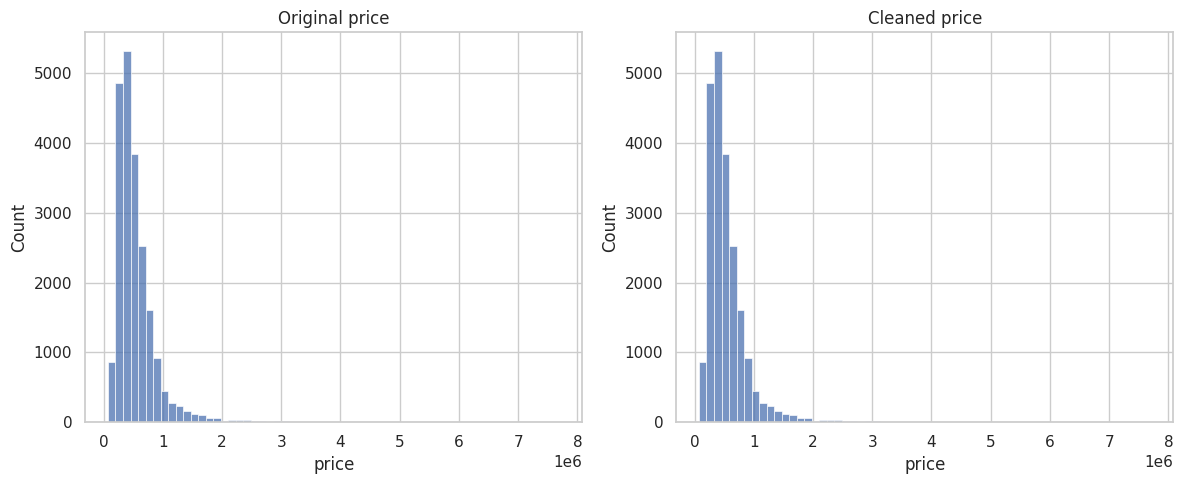

In [43]:
fig, axes = plt.subplots(1,2, figsize=(12,5))
sns.histplot(df["price"], bins=60, ax=axes[0])
axes[0].set_title("Original price")
sns.histplot(df_clean["price"], bins=60, ax=axes[1])
axes[1].set_title("Cleaned price")
plt.tight_layout()
plt.show()


## 25. Final Findings

Use the computed tables and graphs above in the report. Discuss:
1. Price distribution and skew (mean vs. median gap).
2. Strongest price drivers: `sqft_living`, `grade`, `bathrooms` (from the correlation matrix).
3. The `bedrooms == 33` data-entry error and how it was corrected.
4. Waterfront and renovation price premiums.
5. IQR outliers in `sqft_lot`, `price`, and `sqft_living` — legitimate luxury/rural properties rather than errors.
6. Location effects visible through `zipcode` and geographic coordinates (worth a separate geo-analysis).
7. Recommendation to model `log_price` instead of raw `price` given the right skew.


## 26. Export Cleaned Dataset

In [44]:
# Uncomment this line if you want to create the cleaned CSV:
# df_clean.to_csv("KC_House_Data_cleaned.csv", index=False)

print("Complete EDA notebook finished.")


Complete EDA notebook finished.
